# 공연 전후 시간대 노출과 외식업 매출

졸업 프로젝트 · 종로구·마포구 · 외식업 10종 · 2023~2025년 분기 자료

**분석 질문:** 예상 공연 종료 후 시간과 많이 겹치는 시간 구간에서 매출의 분기별 시간대 패턴도 달라지는가?

공연 시간은 수집 시점의 요일별 안내와 러닝타임을 반복 적용한 **예정 일정**이다. 실제 회차·관람객·정확한 공연 후 매출이 아니다. 원래 분기 매출의 여섯 구간을 그대로 사용하며, 매출을 시간 비율로 나누거나 일별로 복원하지 않는다. 기존 01~08 분석과 결과는 변경하지 않는다.

실행 순서: 09 공연 노출 → 10 시간대 매출 → 이 노트북. 분석은 로컬 고정 자료만 사용한다.

In [1]:
from pathlib import Path
import os
for variable in ['OPENBLAS_NUM_THREADS','MKL_NUM_THREADS','OMP_NUM_THREADS']:
    os.environ[variable]='1'
import json, hashlib, platform
from datetime import datetime, timezone
import numpy as np
import pandas as pd
from scipy import linalg, stats
from statsmodels.stats.multitest import multipletests
from IPython.display import display, Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'AGENTS.md').is_file() and (p/'data/raw').is_dir())
D=ROOT/'data/analysis/final/time_windows'
R=ROOT/'results/main/time_windows'
R.mkdir(parents=True,exist_ok=True)
F=R/'figures'; F.mkdir(exist_ok=True)
def sha(path): return hashlib.sha256(path.read_bytes()).hexdigest()
def read_json(path): return json.loads(path.read_text(encoding='utf-8'))
BINS=['00_06','06_11','11_14','14_17','17_21','21_24']
WINDOWS={'post03':'종료 후 0~3시간','post36':'종료 후 3~6시간','post06':'종료 후 0~6시간','pre03':'시작 전 3시간'}
KEY=['area_id','industry_id','quarter','time_bin']
BASE_KEY=KEY[:3]
INDUSTRY_IDS=[f'CS100{i:03d}' for i in range(1,11)]
pd.set_option('display.max_rows',45)
pd.set_option('display.float_format',lambda v:f'{v:,.5f}')

## 결과를 보기 전에 고정한 분석 계획

주요 시간창은 **종료 후 0~3시간**, 나머지는 보조다. 창별 모형을 별도로 추정하며, 0~6시간은 0~3시간과 3~6시간의 누적 창이다. 시작 전 3시간은 실제 사전 소비가 생길 수 있어 위약 검정으로 취급하지 않는다.

주표본은 공연 ID 기준 일정 가용률 **90% 이상**인 상권·분기다. 파싱 가능한 공연의 노출 부분합을 사용하고 나머지 공연의 활동이 0이라고 가정하지 않는다. 이 가용률은 관객 수나 회차 기준 포괄률이 아니다. 100% 가용 표본을 별도 민감도 분석한다. 90% 기준은 결과를 보기 전에 실무적 품질 기준으로 정했으며 오류가 제거되는 경계는 아니다.

전 업종 공통 기울기 4개를 Holm 보정, 업종별 4창×10종의 40개 기울기를 BH 보정한다. 업종 간 기울기 동일성 검정 4개는 별도 Holm 보정한다. 미추정 항목은 보정 계산에서 p=1, 결과표에서는 미추정으로 남긴다. 이 확장 자체는 기존 결과를 본 뒤 설계한 탐색 분석이다.

In [2]:
PLAN={'version':1,'primary_window':'post03','windows':list(WINDOWS),'radius_m':500,
 'outcome':'log1p_timebin_sales_amount','primary_coverage_pct':90.0,'sensitivity_coverage_pct':100.0,
 'primary_fixed_effects':['area_industry_timebin','industry_quarter_timebin','area_industry_quarter'],
 'comparison_fixed_effects':['area_industry_timebin','industry_quarter_timebin'],
 'common_slope_family':'4 windows Holm','industry_slope_family':'4 windows x 10 industries BH (40)',
 'industry_equality_family':'4 windows Holm','minimum_industry_clusters':20,
 'minimum_quarters_per_area_industry':2,'cluster':'area_id','confidence_intervals':'individual 95%, t(G-1)',
 'exposure_units':'sum overlapping scheduled-window minutes / 180; post06=post03+post36',
 'missing_sales_zero_filled':False,'incomplete_exposure':'known partial sum, gated by ID availability',
 'exact_event_window_sales':False,'confirmatory_analysis':False}
plan_path=ROOT/'metadata/main/time_window_plan.json'
if plan_path.exists():
    assert read_json(plan_path)['plan']==PLAN,'분석 계획 변경은 별도 버전으로 기록해야 합니다.'
else:
    plan_path.write_text(json.dumps({'frozen_before_model_fitting_utc':datetime.now(timezone.utc).isoformat(),'plan':PLAN},ensure_ascii=False,indent=2),encoding='utf-8')
display(pd.DataFrame([{'항목':k,'설정':str(v)} for k,v in PLAN.items() if k in ['primary_window','primary_coverage_pct','common_slope_family','industry_slope_family','cluster']]))

,항목,설정
0,primary_window,post03
1,primary_coverage_pct,90.0
2,common_slope_family,4 windows Holm
3,industry_slope_family,4 windows x 10 industries BH (40)
4,cluster,area_id


## 고정 입력과 원자료 연결

6개 매출 구간은 00~06, 06~11, 11~14, 14~17, 17~21, 21~24시다. 시간폭이 서로 다르며 시간대 고정효과가 고정된 수준 차이를 반영한다. 원래 매출이 없는 상권·업종·분기는 전 구간 결측으로 유지한다. 한 분기의 여섯 행은 여섯 개의 독립적인 공연 관측치가 아니다.

**예정노출 단위:** 각 예정회차의 시간창이 매출 구간과 겹치는 분을 180으로 나눠 합산한다. 종료 후 0~3시간의 전체 구간 합계는 회차당 1, 누적 0~6시간은 회차당 2다. 시간창이 날짜·분기를 넘으면 겹친 날짜·분기에 배분한다. 이는 공연 노출 지표의 배분이며 매출액 배분이 아니다.

가령 19:00 시작·러닝타임 90분인 가상의 공연은 20:30에 끝난다고 추정한다. 종료 후 0~3시간(20:30~23:30)은 17~21시 구간에 30/180, 21~24시 구간에 150/180의 예정노출을 더한다. 실제 그 시간의 매출을 관측했다는 뜻은 아니다.

In [3]:
input_paths=[D/'sales_time_panel.csv',D/'area_quarter_timebin_exposure.csv',D/'availability.csv',
 R/'09_exposure_summary.json',R/'10_sales_summary.json',ROOT/'data/analysis/final/food_industry_panel.csv',plan_path]
assert all(p.exists() for p in input_paths),'09와 10 노트북을 먼저 실행하세요.'
input_hashes={p.relative_to(ROOT).as_posix():sha(p) for p in input_paths}
for source_path,digest in read_json(R/'10_sales_summary.json')['output_sha256'].items():
    assert sha(ROOT/source_path)==digest,source_path
for source_path,record in read_json(R/'09_exposure_summary.json')['outputs'].items():
    assert sha(ROOT/source_path)==record['sha256'],source_path
protected_paths=[ROOT/'results/main/baseline/09_industry_effects.csv',ROOT/'results/main/baseline/10_gee_industry_effects.csv']
protected_hashes={p.relative_to(ROOT).as_posix():sha(p) for p in protected_paths}
metadata=read_json(ROOT/'results/main/baseline/08_food_scope_metadata.json')
assert sha(ROOT/'data/analysis/final/food_industry_panel.csv')==metadata['panel_sha256']
sales=pd.read_csv(D/'sales_time_panel.csv',dtype={k:str for k in KEY})
expo=pd.read_csv(D/'area_quarter_timebin_exposure.csv',dtype={k:str for k in ['area_id','quarter','time_bin']})
assert not sales.duplicated(KEY).any() and not expo.duplicated(['area_id','quarter','time_bin']).any()
assert set(sales.time_bin)==set(expo.time_bin)==set(BINS)
xcols=[f'known_exposure_{w}' for w in WINDOWS]
assert set(xcols+['availability_pct']).issubset(expo.columns)
assert expo[xcols].ge(0).all().all()
assert np.allclose(expo.known_exposure_post06,expo.known_exposure_post03+expo.known_exposure_post36)
panel=sales.merge(expo[['area_id','quarter','time_bin','availability_pct']+xcols],on=['area_id','quarter','time_bin'],how='left',validate='many_to_one',indicator=True)
assert panel['_merge'].eq('both').all(); panel=panel.drop(columns='_merge')
assert len(panel)==108720 and panel.groupby(BASE_KEY).time_bin.nunique().eq(6).all()
panel['y']=np.log1p(panel['sales_amount'].where(panel['sales_amount'].ge(0)))
INDUSTRIES=panel[['industry_id','industry']].drop_duplicates().set_index('industry_id')['industry'].to_dict()
assert set(INDUSTRIES)==set(INDUSTRY_IDS)
display(pd.DataFrame([{'전체 시간대 행':len(panel),'상권·업종·분기 조합':panel[BASE_KEY].drop_duplicates().shape[0],
 '매출 제공 시간대행':panel.y.notna().sum(),'상권 수':panel.area_id.nunique()}]).rename(columns={'전체 시간대 행':'전체 시간대 행','상권·업종·분기 조합':'상권·업종·분기 조합'}))

,전체 시간대 행,상권·업종·분기 조합,매출 제공 시간대행,상권 수
0,108720,18120,45966,151


## 표본과 가용률

주분석은 여섯 구간 모두 비음수 매출이 관측된 상권·업종·분기만 사용한다. 2분기 미만으로 남는 상권·업종은 제거한다. 결측 구간을 0으로 바꾸지 않는다. 90% 표본과 100% 표본의 차이는 일정 정보의 가용성에 따른 선택이기도 하다.

In [4]:
sample_rows=[]
def prepare(window,threshold=90):
    p=panel.loc[panel.availability_pct.ge(threshold)].copy()
    p['x']=np.log1p(p['known_exposure_'+window])
    valid=p[['y','x']].notna().all(axis=1)
    eligible=valid.groupby([p[k] for k in BASE_KEY]).transform('sum').eq(6)
    p=p.loc[valid & eligible]
    qs=p.groupby(['area_id','industry_id']).quarter.transform('nunique')
    p=p.loc[qs.ge(2)].sort_values(['industry_id','time_bin','area_id','quarter']).reset_index(drop=True)
    assert p.groupby(BASE_KEY).size().eq(6).all()
    return p
for threshold in [90,100]:
    p=prepare('post03',threshold)
    for ind in INDUSTRY_IDS:
        g=p.loc[p.industry_id.eq(ind)]
        sample_rows.append({'coverage_threshold':threshold,'industry_id':ind,'industry':INDUSTRIES[ind],
         'timebin_rows':len(g),'area_industry_quarters':len(g)//6,'area_clusters':g.area_id.nunique(),
         'median_id_availability_pct':g.availability_pct.median()})
sample_table=pd.DataFrame(sample_rows)
display(sample_table)
coverage_table=expo[['area_id','quarter','availability_pct']].drop_duplicates().assign(
 coverage_group=lambda d:pd.cut(d.availability_pct,[-.01,79.999999,89.999999,99.999999,100],labels=['80% 미만','80~90% 미만','90~100% 미만','100%']))
display(coverage_table.groupby('coverage_group',observed=False).size().rename('상권·분기 수').to_frame())

,coverage_threshold,industry_id,industry,timebin_rows,area_industry_quarters,area_clusters,median_id_availability_pct
0,90,CS100001,한식음식점,6732,1122,117,100.00000
1,90,CS100002,중식음식점,1956,326,40,98.24944
2,90,CS100003,일식음식점,2094,349,39,97.62846
3,90,CS100004,양식음식점,2880,480,56,97.89474
4,90,CS100005,제과점,2400,400,45,98.05187
5,90,CS100006,패스트푸드점,1842,307,36,97.56098
6,90,CS100007,치킨전문점,2178,363,43,100.00000
7,90,CS100008,분식전문점,3870,645,70,100.00000
8,90,CS100009,호프-간이주점,4284,714,77,100.00000
9,90,CS100010,커피-음료,5904,984,107,100.00000


,상권·분기 수
coverage_group,
80% 미만,138
80~90% 미만,293
90~100% 미만,520
100%,861


## 주모형: 시간대별 상대 매출 패턴

**log(1+매출ₐɡqᵦ) = 상권×업종×시간대 FE + 업종×분기×시간대 FE + 상권×업종×분기 FE + β × log(1+예정노출ₐqᵦ) + 오차**

같은 상권·업종의 같은 분기에서 전반적인 매출 수준이 늘어나는 부분은 제거한다. 따라서 β는 **분기 공통 수준을 넘어서는 시간대별 상대 패턴**의 관련성이며 총매출 증가 효과가 아니다. 상권×업종×분기 효과를 빼지 않은 기존 방식의 확장 모형은 별도 비교로 둔다.

여섯 구간이 완전히 같은 표본이므로 각 상권·업종·분기에서 6구간 평균을 먼저 제거하고, 각 구간에서 상권·분기 효과를 제거할 수 있다. 작은 불균형 표본에서 명시적 더미 회귀와 대조해 검증한다.

In [5]:
def absorb_area_quarter(part,values):
    arr=pd.DataFrame(values,index=part.index)
    target=arr-arr.groupby(part.area_id).transform('mean')
    q=pd.get_dummies(part.quarter,dtype=float)
    qdm=q-q.groupby(part.area_id).transform('mean')
    fit,_,rank,_=linalg.lstsq(qdm.to_numpy(),target.to_numpy(),cond=1e-10,lapack_driver='gelsd')
    residual=target.to_numpy()-qdm.to_numpy()@fit
    return residual,int(part.area_id.nunique()+rank)

def absorb_time_effects(part,columns,three_way=True):
    target=part[columns].astype(float).copy()
    if three_way:
        target=target-target.groupby([part.area_id,part.quarter]).transform('mean')
    result=np.empty((len(part),len(columns))); ranks=[]
    for time_bin in BINS:
        ix=np.flatnonzero(part.time_bin.eq(time_bin).to_numpy())
        residual,rank=absorb_area_quarter(part.iloc[ix],target.iloc[ix].to_numpy())
        result[ix]=residual; ranks.append(rank)
    assert len(set(ranks))==1
    M=part[['area_id','quarter']].drop_duplicates().shape[0]
    nuisance_rank=M+5*ranks[0] if three_way else 6*ranks[0]
    return result,nuisance_rank

def model_blocks(frame,three_way=True):
    blocks=[]; audit=[]
    for ind in INDUSTRY_IDS:
        part=frame.loc[frame.industry_id.eq(ind)].reset_index(drop=True)
        g=part.area_id.nunique()
        if g<20:
            audit.append({'industry_id':ind,'status':'too_few_clusters','clusters':g,'rows':len(part)})
            continue
        z,rank=absorb_time_effects(part,['y','x'],three_way)
        info=float(z[:,1]@z[:,1])
        ok=info>1e-10
        audit.append({'industry_id':ind,'status':'estimated' if ok else 'no_within_variation',
          'clusters':g,'rows':len(part),'nuisance_rank':rank,'residual_x_sd':float(z[:,1].std())})
        if ok: blocks.append({'industry_id':ind,'frame':part,'y':z[:,0],'x':z[:,1],'rank':rank})
    return blocks,audit

### 계산 검증

임의로 만든 작은 자료에서 일부 상권·분기 조합을 제외해 불균형 표본을 만든다. 모든 남은 조합은 여섯 시간대를 유지한다. 빠른 흡수 계산의 잔차와 고정효과 순위를 명시적 더미 회귀와 비교한다. 실제 결과를 맞추기 위한 검사가 아니라 모형 구현 오류를 확인하는 검사다.

In [6]:
rng=np.random.default_rng(20261005)
toy=pd.MultiIndex.from_product([['a','b','c','d'],['q1','q2','q3','q4'],BINS],names=['area_id','quarter','time_bin']).to_frame(index=False)
toy=toy.loc[~((toy.area_id.eq('a') & toy.quarter.eq('q2'))|(toy.area_id.eq('c') & toy.quarter.eq('q4')))].reset_index(drop=True)
toy['y']=rng.normal(size=len(toy)); toy['x']=rng.normal(size=len(toy))
validation_rows=[]
for three in [False,True]:
    groups=[toy.area_id+'|'+toy.time_bin,toy.quarter+'|'+toy.time_bin]
    if three: groups.append(toy.area_id+'|'+toy.quarter)
    dummy=np.column_stack([pd.get_dummies(g,dtype=float).to_numpy() for g in groups])
    coef,_,rank,_=linalg.lstsq(dummy,toy[['y','x']].to_numpy(),cond=1e-10,lapack_driver='gelsd')
    expected=toy[['y','x']].to_numpy()-dummy@coef
    observed,nuisance=absorb_time_effects(toy,['y','x'],three)
    err=float(np.max(np.abs(expected-observed)))
    assert err<1e-10 and rank==nuisance,(err,rank,nuisance)
    validation_rows.append({'check':'threeway_dummy_equivalence' if three else 'twoway_dummy_equivalence','passed':True,'max_error':err,'rank':rank})
display(pd.DataFrame(validation_rows))

,check,passed,max_error,rank
0,twoway_dummy_equivalence,True,0.00000,42
1,threeway_dummy_equivalence,True,0.00000,49


## 상권 군집 추론

모든 업종·시간대의 오차 기여를 같은 상권 안에서 합쳐 군집 공분산을 계산한다. 6개 시간대로 행을 늘렸다는 이유로 독립 표본 수를 늘리지 않는다. 자유도는 사용된 상권 군집 수−1이며, 전체 모형의 고정효과 순위를 반영한 소표본 보정을 적용한다. 인접 상권 사이의 공간 상관까지 해결한 것은 아니다.

In [7]:
def fit_system(blocks,common=False):
    assert blocks,'추정 가능한 업종이 없습니다.'
    P=1 if common else len(blocks)
    area_ids=sorted(set().union(*(set(b['frame'].area_id) for b in blocks)))
    area_map={a:i for i,a in enumerate(area_ids)}
    G=len(area_ids); N=sum(len(b['x']) for b in blocks)
    K=sum(b['rank'] for b in blocks)+P
    assert G>1 and N>K
    xtx=np.zeros(P); xty=np.zeros(P)
    for i,b in enumerate(blocks):
        j=0 if common else i
        xtx[j]+=b['x']@b['x']; xty[j]+=b['x']@b['y']
    beta=xty/xtx
    scores=np.zeros((G,P))
    for i,b in enumerate(blocks):
        j=0 if common else i
        residual=b['y']-b['x']*beta[j]
        codes=b['frame'].area_id.map(area_map).to_numpy()
        np.add.at(scores[:,j],codes,b['x']*residual)
    correction=G/(G-1)*(N-1)/(N-K)
    cov=correction*(scores.T@scores)/np.outer(xtx,xtx)
    assert np.isfinite(beta).all() and np.isfinite(cov).all() and np.diag(cov).min()>0
    return {'beta':beta,'cov':cov,'clusters':G,'nobs':N,'rank':K,'df':G-1,'correction':correction}

def coefficient_row(m,index=0):
    beta=float(m['beta'][index]); se=float(np.sqrt(m['cov'][index,index])); crit=stats.t.ppf(.975,m['df'])
    return {'coefficient':beta,'standard_error':se,'ci_low':beta-crit*se,'ci_high':beta+crit*se,
      'p_value':float(2*stats.t.sf(abs(beta/se),m['df'])),'nobs':m['nobs'],
      'clusters':m['clusters'],'df':m['df'],'rank':m['rank'],'cluster_correction':m['correction']}

def equality_test(m):
    k=len(m['beta'])
    if k<2: return {'F':np.nan,'df_num':0,'p_value':np.nan,'status':'not_estimable'}
    C=np.column_stack([-np.ones(k-1),np.eye(k-1)])
    diff=C@m['beta']; V=C@m['cov']@C.T
    if np.linalg.matrix_rank(V)<k-1: return {'F':np.nan,'df_num':k-1,'p_value':np.nan,'status':'singular_covariance'}
    Fstat=float(diff@np.linalg.solve(V,diff)/(k-1))
    return {'F':Fstat,'df_num':k-1,'df_den':m['df'],'p_value':float(stats.f.sf(Fstat,k-1,m['df'])),'status':'estimated'}

In [8]:
import statsmodels.api as sm
from statsmodels.stats.sandwich_covariance import cov_cluster
z,rank=absorb_time_effects(toy,['y','x'],True)
toy_model=fit_system([{'frame':toy,'x':z[:,1],'y':z[:,0],'rank':rank}],common=True)
groups=[toy.area_id+'|'+toy.time_bin,toy.quarter+'|'+toy.time_bin,toy.area_id+'|'+toy.quarter]
dummy=np.column_stack([pd.get_dummies(g,dtype=float).to_numpy() for g in groups])
_,_,piv=linalg.qr(dummy,mode='economic',pivoting=True)
design=np.column_stack([dummy[:,piv[:rank]],toy.x.to_numpy()])
explicit=sm.OLS(toy.y.to_numpy(),design).fit()
expected_cov=cov_cluster(explicit,toy.area_id,use_correction=False)*toy_model['correction']
beta_error=float(abs(explicit.params[-1]-toy_model['beta'][0]))
var_error=float(abs(expected_cov[-1,-1]-toy_model['cov'][0,0]))
assert beta_error<1e-10 and var_error<1e-10
validation_rows.append({'check':'explicit_ols_cluster_covariance','passed':True,'max_error':max(beta_error,var_error),'rank':rank+1})
display(pd.DataFrame(validation_rows))

,check,passed,max_error,rank
0,twoway_dummy_equivalence,True,0.00000,42
1,threeway_dummy_equivalence,True,0.00000,49
2,explicit_ols_cluster_covariance,True,0.00000,50


## 네 시간창의 공통 기울기와 업종별 기울기

같은 주표본에서 각 시간창을 따로 적합한다. 0~6시간 노출은 다른 두 종료 후 창의 합이므로 동시에 넣지 않는다. 공통 기울기는 매출액 합계를 회귀한 값이 아니라 10개 업종의 관측 패널에서 동일한 기울기를 가정한 결과다. 업종별 비교 모형은 이 가정을 풀어 각각 추정한다.

In [9]:
common_rows=[]; industry_rows=[]; omnibus_rows=[]; eligibility_rows=[]; models={}; information_rows=[]
for window in WINDOWS:
    frame=prepare(window,90)
    blocks,audit=model_blocks(frame,True)
    eligibility_rows.extend([dict(window=window,**a) for a in audit])
    common=fit_system(blocks,True); heterogeneous=fit_system(blocks,False)
    models[window]=(blocks,common,heterogeneous)
    common_rows.append(dict(window=window,label=WINDOWS[window],estimated_industries=len(blocks),**coefficient_row(common)))
    ids=[b['industry_id'] for b in blocks]
    for ind in INDUSTRY_IDS:
        row={'window':window,'label':WINDOWS[window],'industry_id':ind,'industry':INDUSTRIES[ind]}
        if ind in ids:
            pos=ids.index(ind); b=blocks[pos]
            row.update(coefficient_row(heterogeneous,pos))
            row.update(status='estimated',industry_clusters=b['frame'].area_id.nunique(),industry_rows=len(b['frame']))
            info=pd.Series(b['x']**2,index=b['frame'].area_id).groupby(level=0).sum()
            shares=(info/info.sum()).sort_values(ascending=False)
            information_rows.append({'window':window,'industry_id':ind,'industry':INDUSTRIES[ind],
              'clusters':len(shares),'top5_information_share':float(shares.head(5).sum()),'residual_x_sd':float(b['x'].std())})
        else: row.update(status='not_estimable',coefficient=np.nan,standard_error=np.nan,ci_low=np.nan,ci_high=np.nan,p_value=np.nan)
        industry_rows.append(row)
    omnibus_rows.append(dict(window=window,label=WINDOWS[window],**equality_test(heterogeneous)))
common_results=pd.DataFrame(common_rows)
industry_results=pd.DataFrame(industry_rows)
omnibus_results=pd.DataFrame(omnibus_rows)
common_results['p_holm_4']=multipletests(common_results.p_value.fillna(1),method='holm')[1]
industry_results['p_bh_40']=multipletests(industry_results.p_value.fillna(1),method='fdr_bh')[1]
industry_results.loc[industry_results.status.ne('estimated'),'p_bh_40']=np.nan
omnibus_results['p_holm_4']=multipletests(omnibus_results.p_value.fillna(1),method='holm')[1]
assert len(industry_results)==40 and len(common_results)==4
for f in [common_results,industry_results]:
    for raw,converted in [('coefficient','doubling_pct'),('ci_low','doubling_ci_low'),('ci_high','doubling_ci_high')]:
        f[converted]=100*np.expm1(f[raw]*np.log(2))
display(common_results[['label','coefficient','ci_low','ci_high','p_value','p_holm_4','nobs','clusters']])

,label,coefficient,ci_low,ci_high,p_value,p_holm_4,nobs,clusters
0,종료 후 0~3시간,-0.04029,-0.10468,0.02411,0.21793,0.87170,34140,125
1,종료 후 3~6시간,-0.01515,-0.07603,0.04573,0.62323,1.00000,34140,125
2,종료 후 0~6시간,-0.03182,-0.10459,0.04094,0.38835,1.00000,34140,125
3,시작 전 3시간,-0.01233,-0.08593,0.06127,0.74073,1.00000,34140,125


In [10]:
sig=common_results.loc[common_results.p_holm_4.lt(.05),'label'].tolist()
primary=common_results.set_index('window').loc['post03']
primary_direction='양' if primary.coefficient>0 else '음'
primary_state='5% 기준을 통과했다' if primary.p_holm_4<.05 else '5% 기준을 통과하지 못했다'
text=(f"**주분석 결과:** 종료 후 0~3시간의 공통 기울기는 {primary.coefficient:+.4f}, "
 f"개별 95% CI [{primary.ci_low:+.4f}, {primary.ci_high:+.4f}], Holm p={primary.p_holm_4:.4g}로 {primary_state}. "
 f"점추정치 방향은 {primary_direction}이다. 4창 전체에서 보정 후 유의한 창은 {len(sig)}개다. "
 '이는 예정 종료 후 시간창과 매출의 상대적 시간대 패턴 사이 관련성이다. '
 '그 공연이 끝난 뒤 실제 매출이 그만큼 늘거나 줄었다는 인과효과, 또는 분기 총매출 변화로 해석할 수 없다.')
display(Markdown(text))

**주분석 결과:** 종료 후 0~3시간의 공통 기울기는 -0.0403, 개별 95% CI [-0.1047, +0.0241], Holm p=0.8717로 5% 기준을 통과하지 못했다. 점추정치 방향은 음이다. 4창 전체에서 보정 후 유의한 창은 0개다. 이는 예정 종료 후 시간창과 매출의 상대적 시간대 패턴 사이 관련성이다. 그 공연이 끝난 뒤 실제 매출이 그만큼 늘거나 줄었다는 인과효과, 또는 분기 총매출 변화로 해석할 수 없다.

### 해석용 환산

아래 수치는 **(1+예정노출)가 2배**가 되는 모형상 비교, 예를 들어 9→19에 대해 `100×[exp(β×ln2)−1]`로 환산했다. 예정노출 자체가 항상 2배라는 뜻이 아니며, 모형의 다른 조건을 고정한 `(시간대 매출+1)`의 조건부 기하평균 상대차이다. 주모형이 분기 공통 수준을 조정하므로 이를 상권 전체 매출 증가율로 읽지 않는다. 시간창별 노출의 분포가 다르므로 창 사이 숫자 크기도 실제 소비 지속시간의 직접 비교가 아니다.

In [11]:
display(common_results[['label','doubling_pct','doubling_ci_low','doubling_ci_high','p_holm_4']])
display(industry_results.loc[industry_results.window.eq('post03'),
 ['industry','coefficient','ci_low','ci_high','p_value','p_bh_40','industry_rows','industry_clusters']])
display(omnibus_results[['label','F','df_num','p_value','p_holm_4']])

,label,doubling_pct,doubling_ci_low,doubling_ci_high,p_holm_4
0,종료 후 0~3시간,-2.75398,-6.99910,1.68492,0.87170
1,종료 후 3~6시간,-1.04451,-5.13326,3.22046,1.00000
2,종료 후 0~6시간,-2.18173,-6.99297,2.87841,1.00000
3,시작 전 3시간,-0.85113,-5.78252,4.33837,1.00000


,industry,coefficient,ci_low,ci_high,p_value,p_bh_40,industry_rows,industry_clusters
0,한식음식점,-0.07404,-0.22356,0.07549,0.32897,0.94568,6732,117
1,중식음식점,-0.03925,-0.19760,0.11909,0.62456,0.94568,1956,40
2,일식음식점,0.05862,-0.17008,0.28731,0.61282,0.94568,2094,39
3,양식음식점,-0.03434,-0.30468,0.23601,0.80192,0.94568,2880,56
4,제과점,0.13882,-0.15049,0.42813,0.34410,0.94568,2400,45
5,패스트푸드점,-0.13417,-0.45690,0.18857,0.41218,0.94568,1842,36
6,치킨전문점,-0.16148,-0.51052,0.18756,0.36160,0.94568,2178,43
7,분식전문점,0.13449,-0.11096,0.37994,0.28025,0.94568,3870,70
8,호프-간이주점,-0.10165,-0.38542,0.18212,0.47965,0.94568,4284,77
9,커피-음료,-0.11848,-0.30219,0.06523,0.20416,0.94568,5904,107


,label,F,df_num,p_value,p_holm_4
0,종료 후 0~3시간,0.57286,9,0.81721,1.00000
1,종료 후 3~6시간,0.81444,9,0.60383,1.00000
2,종료 후 0~6시간,0.47939,9,0.88619,1.00000
3,시작 전 3시간,0.43068,9,0.91638,1.00000


## 모든 업종·시간창 결과

개별 95% 구간은 다중비교 동시 구간이 아니다. 색과 결론은 40개 업종 검정의 BH 보정값을 기준으로 한다. 특정 업종에서만 유의하고 다른 업종에서 유의하지 않다는 사실만으로 업종 간 차이를 입증할 수 없다.

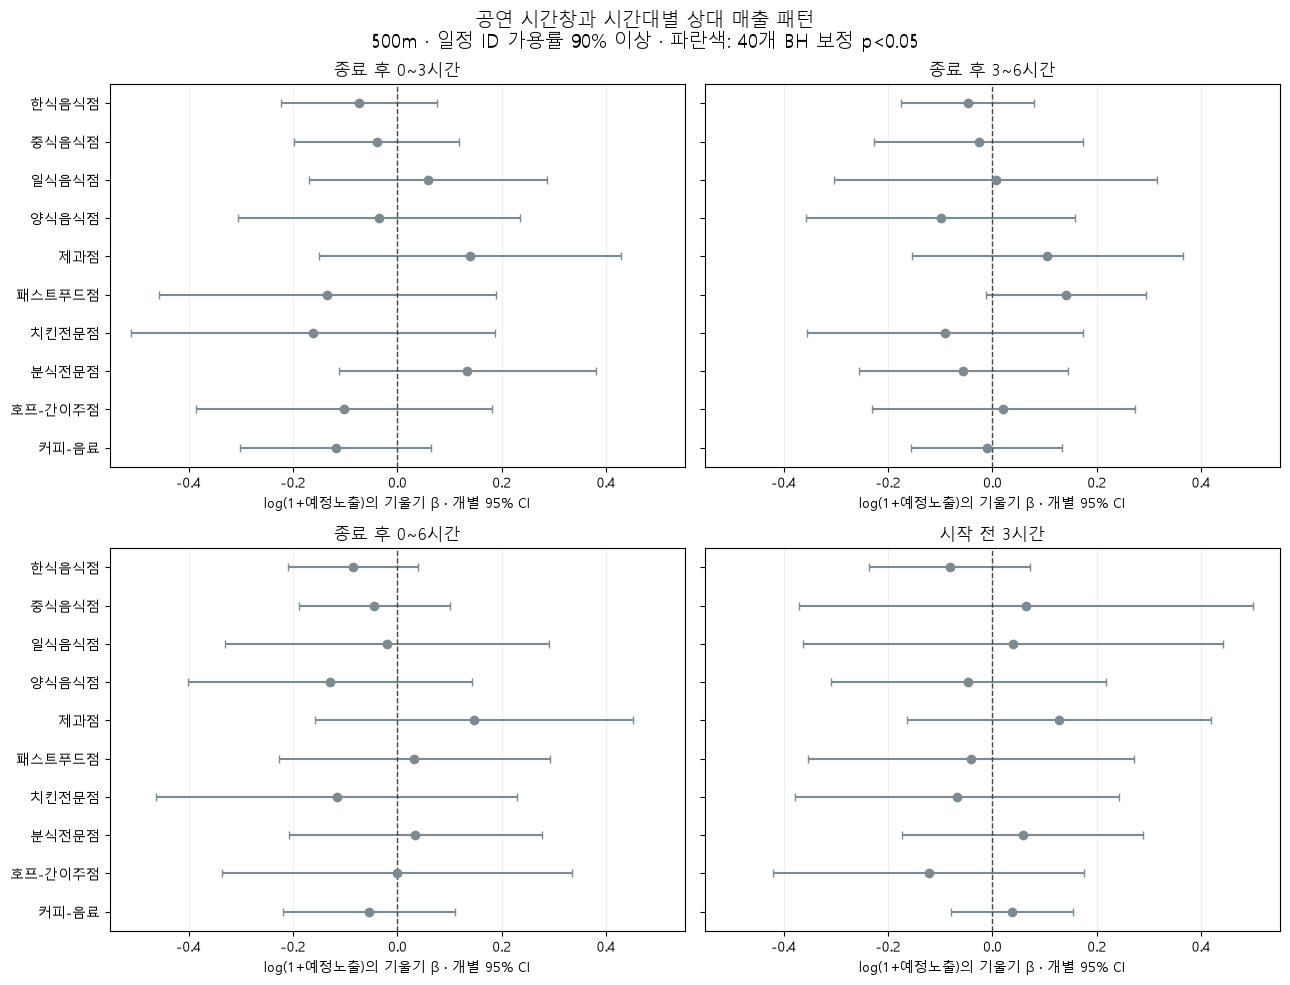

,label,industry,coefficient,ci_low,ci_high,p_value,p_bh_40,status
0,종료 후 0~3시간,한식음식점,-0.07404,-0.22356,0.07549,0.32897,0.94568,estimated
1,종료 후 0~3시간,중식음식점,-0.03925,-0.19760,0.11909,0.62456,0.94568,estimated
2,종료 후 0~3시간,일식음식점,0.05862,-0.17008,0.28731,0.61282,0.94568,estimated
3,종료 후 0~3시간,양식음식점,-0.03434,-0.30468,0.23601,0.80192,0.94568,estimated
4,종료 후 0~3시간,제과점,0.13882,-0.15049,0.42813,0.34410,0.94568,estimated
5,종료 후 0~3시간,패스트푸드점,-0.13417,-0.45690,0.18857,0.41218,0.94568,estimated
6,종료 후 0~3시간,치킨전문점,-0.16148,-0.51052,0.18756,0.36160,0.94568,estimated
7,종료 후 0~3시간,분식전문점,0.13449,-0.11096,0.37994,0.28025,0.94568,estimated
8,종료 후 0~3시간,호프-간이주점,-0.10165,-0.38542,0.18212,0.47965,0.94568,estimated
9,종료 후 0~3시간,커피-음료,-0.11848,-0.30219,0.06523,0.20416,0.94568,estimated


In [12]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
fonts={f.name for f in fm.fontManager.ttflist}
plt.rcParams['font.family']=next((x for x in ['Malgun Gothic','NanumGothic','AppleGothic'] if x in fonts),'DejaVu Sans')
plt.rcParams.update({'axes.unicode_minus':False,'font.size':10})
fig,axes=plt.subplots(2,2,figsize=(13,10),sharey=True)
limit=1.08*max(industry_results.ci_low.abs().max(),industry_results.ci_high.abs().max())
for ax,(window,label) in zip(axes.flat,WINDOWS.items()):
    part=industry_results.loc[industry_results.window.eq(window)].set_index('industry_id').reindex(INDUSTRY_IDS)
    for i,row in enumerate(part.itertuples()):
        if not np.isfinite(row.coefficient): continue
        ax.errorbar(row.coefficient,i,xerr=[[row.coefficient-row.ci_low],[row.ci_high-row.coefficient]],
          fmt='o',capsize=3,color='#186A85' if row.p_bh_40<.05 else '#7D8A91')
    ax.set_yticks(range(10),[INDUSTRIES[i] for i in INDUSTRY_IDS]); ax.set_ylim(9.5,-.5)
    ax.axvline(0,color='#444444',ls='--',lw=1); ax.grid(axis='x',alpha=.2)
    ax.set_xlim(-limit,limit); ax.set_title(label); ax.set_xlabel('log(1+예정노출)의 기울기 β · 개별 95% CI')
fig.suptitle('공연 시간창과 시간대별 상대 매출 패턴\n500m · 일정 ID 가용률 90% 이상 · 파란색: 40개 BH 보정 p<0.05',fontsize=14)
fig.tight_layout()
fig.savefig(F/'11_time_window_industries.png',dpi=160,bbox_inches='tight')
plt.show(); plt.close(fig)
display(industry_results[['label','industry','coefficient','ci_low','ci_high','p_value','p_bh_40','status']])

## 표본·모형을 바꾼 확인

주분석 결과를 확인하기 전에 정한 두 보조 설정이다. **100% 가용 표본**은 누락 일정 ID가 없는 집단만 이용하므로 표본 구성이 달라진다. **분기 공통 수준 미조정**은 상권×업종×분기 고정효과를 제외한 기존 방식의 확장이다. 후자는 상대 패턴과 분기 전반의 수요 변화가 함께 들어가는 다른 추정 대상이다. 두 설정 모두 종료 후 0~3시간만 확인한다. 아래 p값은 보정 전 값이며 주검정을 대체하지 않는다.

In [13]:
sensitivity_rows=[]
for name,threshold,three in [('주모형',90,True),('100% 일정 가용 표본',100,True),('분기 공통 수준 미조정',90,False)]:
    frame=prepare('post03',threshold); blocks,audit=model_blocks(frame,three)
    if not blocks:
        sensitivity_rows.append({'scenario':name,'coverage_threshold':threshold,'status':'not_estimable'})
        continue
    m=fit_system(blocks,True)
    sensitivity_rows.append({'scenario':name,'coverage_threshold':threshold,'three_way':three,'status':'estimated','estimated_industries':len(blocks),'included_industries':','.join(b['industry_id'] for b in blocks),**coefficient_row(m)})
sensitivity=pd.DataFrame(sensitivity_rows)
display(sensitivity[['scenario','estimated_industries','coefficient','ci_low','ci_high','p_value','nobs','clusters']])
information=pd.DataFrame(information_rows)
display(information.loc[information.window.eq('post03')])
full=sensitivity.loc[sensitivity.coverage_threshold.eq(100)].iloc[0]
included=set(full.included_industries.split(','))
excluded=[INDUSTRIES[i] for i in INDUSTRY_IDS if i not in included]
display(Markdown(f'**100% 가용률 표본은 {int(full.estimated_industries)}개 업종 모형이다.** 최소 20개 상권 군집 조건으로 '+', '.join(excluded)+' 업종은 제외됐다. 주모형 10종과 같은 구성의 반복 검증이 아니며 표본·가중의 차이를 함께 고려해야 한다.'))

,scenario,estimated_industries,coefficient,ci_low,ci_high,p_value,nobs,clusters
0,주모형,10,-0.04029,-0.10468,0.02411,0.21793,34140,125
1,100% 일정 가용 표본,8,-0.06704,-0.21948,0.08540,0.38434,15906,86
2,분기 공통 수준 미조정,10,-0.02294,-0.07631,0.03043,0.39657,34140,125


,window,industry_id,industry,clusters,top5_information_share,residual_x_sd
0,post03,CS100001,한식음식점,117,0.15403,0.37957
1,post03,CS100002,중식음식점,40,0.33423,0.41283
2,post03,CS100003,일식음식점,39,0.28545,0.40916
3,post03,CS100004,양식음식점,56,0.21144,0.41779
4,post03,CS100005,제과점,45,0.26897,0.39795
5,post03,CS100006,패스트푸드점,36,0.29620,0.39225
6,post03,CS100007,치킨전문점,43,0.29666,0.37049
7,post03,CS100008,분식전문점,70,0.21484,0.39372
8,post03,CS100009,호프-간이주점,77,0.19532,0.39984
9,post03,CS100010,커피-음료,107,0.15801,0.39857


**100% 가용률 표본은 8개 업종 모형이다.** 최소 20개 상권 군집 조건으로 일식음식점, 패스트푸드점 업종은 제외됐다. 주모형 10종과 같은 구성의 반복 검증이 아니며 표본·가중의 차이를 함께 고려해야 한다.

## 해석의 범위와 남은 한계

- **시간 정렬을 개선한 관련성 분석:** 정확한 회차별 종료 후 매출이 아니다. 분기 집계의 시간 해상도 한계가 남는다.
- **예정 일정 반복 가정:** HOL 특별 일정, 실제 취소·휴연·지연과 2023~2025년의 역사적 일정 변경을 모두 확인하지 못했다. 일정이 겹치거나 러닝타임이 비정상인 ID는 노출 구축에서 제외하고 가용률에 반영했다.
- **누락 노출:** 90%는 ID 기준이다. 누락 10%가 장기 공연이면 실제 활동 비중은 더 클 수 있다. 알려진 부분합과 실제 전체 노출를 구분한다. 100%도 안내문이 정확하다는 뜻은 아니다.
- **공간·소비자 식별:** 같은 공연은 여러 상권에 연결될 수 있고 같은 시간의 여러 공연은 예정회차 노출로 합산된다. 고유 관객 수나 실제 소비자 수가 아니다. 상권 간 잔차 공간 상관은 별도 검증하지 않았다.
- **실제 0원과 로그 변환:** 심야·오전 등 일부 구간은 원자료에서 실제 0원이다. 이 값은 결측과 구분해 유지했다. log(1+원) 모형에는 0원과 양수 매출 사이 이동도 반영되므로 순수한 양수 매출의 성장률 모형이 아니다. 화폐 단위와 로그 변환 선택에 민감할 수 있다.
- **선택과 다중검정:** 소규모 상권·업종의 미제공, 서로 다른 업종의 표본, 12개 분기만의 제한이 유지된다. 신규 유의 결과가 나오더라도 기존 결과를 보고 확장한 탐색적 결과이며 새 기간의 재현이 필요하다.

다음 단계는 실제 회차 일정과 날짜별 세부시간대 매출의 확보다. 현재의 6구간 매출을 시간 비율로 나눠 정확한 사후 매출처럼 만들지 않는다.

In [14]:
primary_industry=industry_results.loc[industry_results.window.eq('post03')]
counts=industry_results.assign(significant=lambda d:d.p_bh_40.lt(.05)).groupby('window').significant.sum()
lines=[f"주표본: {int(primary.nobs):,}개 시간대 행, {int(primary.nobs)//6:,}개 상권·업종·분기, {int(primary.clusters)}개 상권 군집.",
 f"종료 후 0~3시간 공통 기울기 {primary.coefficient:+.4f}, 개별 95% CI [{primary.ci_low:+.4f},{primary.ci_high:+.4f}], Holm p={primary.p_holm_4:.4g}.",
 f"40개 업종별 검정 중 BH 보정 후 유의한 항목은 {int(industry_results.p_bh_40.lt(.05).sum())}개이고, 종료 후 0~3시간에서는 {int(primary_industry.p_bh_40.lt(.05).sum())}개다.",
 '같은 분기의 전반적 매출 수준을 조정한 시간대 상대 패턴이므로 공연으로 인한 총매출 증가나 개별 관람객의 소비로 해석하지 않는다.']
display(Markdown('### 이번 확장의 결론'+chr(10)*2+(chr(10)*2).join(lines)))
outputs={'11_common_effects.csv':common_results,'11_industry_effects.csv':industry_results,
 '11_omnibus_tests.csv':omnibus_results,'11_sensitivity.csv':sensitivity,'11_sample_flow.csv':sample_table,
 '11_eligibility.csv':pd.DataFrame(eligibility_rows),'11_information_concentration.csv':information,
 '11_implementation_checks.csv':pd.DataFrame(validation_rows)}
for name,frame in outputs.items(): frame.to_csv(R/name,index=False,encoding='utf-8-sig')
assert all(sha(ROOT/path)==digest for path,digest in input_hashes.items())
assert all(sha(ROOT/path)==digest for path,digest in protected_hashes.items())
summary={'created_utc':datetime.now(timezone.utc).isoformat(),'plan':PLAN,'input_sha256':input_hashes,
 'protected_baseline_sha256':protected_hashes,'baseline_unchanged':True,'input_unchanged':True,
 'primary':primary.to_dict(),'common_holm_significant_windows':sig,
 'industry_bh_significant_count':int(industry_results.p_bh_40.lt(.05).sum()),
 'conclusions':lines,'network_requests':0,'implementation_checks_passed':len(validation_rows),
 'python':platform.python_version(),'output_sha256':{name:sha(R/name) for name in outputs}}
(R/'11_analysis_summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')
print('결과 저장·기존 결과 불변 확인 완료')

### 이번 확장의 결론

주표본: 34,140개 시간대 행, 5,690개 상권·업종·분기, 125개 상권 군집.

종료 후 0~3시간 공통 기울기 -0.0403, 개별 95% CI [-0.1047,+0.0241], Holm p=0.8717.

40개 업종별 검정 중 BH 보정 후 유의한 항목은 0개이고, 종료 후 0~3시간에서는 0개다.

같은 분기의 전반적 매출 수준을 조정한 시간대 상대 패턴이므로 공연으로 인한 총매출 증가나 개별 관람객의 소비로 해석하지 않는다.

결과 저장·기존 결과 불변 확인 완료
